In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
import optuna

In [2]:
ARTIFACT_DIR = Path("traffic_priority_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

random_state = 42

approaches = ["north", "south", "east", "west"]

target_features = [
    "waiting",
    "queue",
    "arrivals",
    "density",
    "speed",
    "pressure"
]

approach_input_features = [
    "queue",
    "waiting",
    "speed",
    "density",
    "pressure",
    "arrivals",
    "departures",
    "emergency",
    "emergency_waiting"
]

global_features = [
    "phase",
    "phase_time",
    "total_vehicles"
]

scenario_column = "scenario_id"

target_columns = [
    "north_priority",
    "south_priority",
    "east_priority",
    "west_priority"
]

lower_percentile = 1
upper_percentile = 99

batch_size = 256
epochs = 150
learning_rate = 1e-3
weight_decay = 1e-5
patience = 15


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [3]:
ARTIFACT_DIR = Path("traffic_priority_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
df = pd.read_csv('/kaggle/input/datasets/pratyushsahu02/intersection-traffic-dataset/traffic_dataset.csv')

In [5]:
df.head()

,scenario_id,seed,time,phase,phase_time,target_action,north_vehicles,north_queue,north_waiting,north_speed,...,ambulance_count,firetruck_count,police_count,total_emergency_waiting,max_emergency_waiting,total_queue,total_vehicles,total_waiting,max_queue,queue_imbalance
0,0,1000,1.0,0,0.0,0,0,0,0.0,0.000000,...,0,0,0,0.0,0.0,0,1,0.000000,0,0
1,0,1000,5.0,0,4.0,0,1,0,0.0,12.650747,...,0,0,0,0.0,0.0,0,3,0.000000,0,0
2,0,1000,10.0,0,9.0,0,2,0,0.0,12.590703,...,0,0,0,0.0,0.0,0,6,0.000000,0,0
3,0,1000,15.0,0,14.0,1,5,0,0.0,12.788129,...,0,0,0,0.0,0.0,1,10,1.666667,1,1
4,0,1000,20.0,0,19.0,1,6,0,0.0,12.713335,...,0,0,0,0.0,0.0,3,14,4.666667,3,3


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 223160 entries, 0 to 223159
Data columns (total 61 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   scenario_id                  223160 non-null  int64  
 1   seed                         223160 non-null  int64  
 2   time                         223160 non-null  float64
 3   phase                        223160 non-null  int64  
 4   phase_time                   223160 non-null  float64
 5   target_action                223160 non-null  int64  
 6   north_vehicles               223160 non-null  int64  
 7   north_queue                  223160 non-null  int64  
 8   north_waiting                223160 non-null  float64
 9   north_speed                  223160 non-null  float64
 10  north_density                223160 non-null  float64
 11  north_pressure               223160 non-null  float64
 12  north_arrivals               223160 non-null  int64  
 13 

In [7]:
df.describe()

,scenario_id,seed,time,phase,phase_time,target_action,north_vehicles,north_queue,north_waiting,north_speed,...,ambulance_count,firetruck_count,police_count,total_emergency_waiting,max_emergency_waiting,total_queue,total_vehicles,total_waiting,max_queue,queue_imbalance
count,223160.000000,223160.000000,223160.000000,223160.000000,223160.000000,223160.00000,223160.000000,223160.000000,223160.000000,223160.000000,...,223160.000000,223160.000000,223160.000000,223160.000000,223160.000000,223160.000000,223160.000000,223160.000000,223160.000000,223160.000000
mean,149.767817,1149.767817,1858.772786,1.104042,15.555722,0.27284,7.207658,4.452725,9.775696,5.717745,...,0.703979,0.355476,0.345035,19.685099,14.573647,17.624377,28.566486,38.801607,8.445940,7.258899
std,86.618919,86.618919,1076.605411,1.047380,12.123909,0.44542,8.869396,7.413278,13.040429,4.738978,...,1.129197,0.698298,0.689795,39.456201,23.014703,24.773433,31.267146,41.757035,9.223918,6.923323
min,0.000000,1000.000000,1.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,75.000000,1075.000000,925.000000,0.000000,5.000000,0.00000,2.000000,0.000000,0.000000,1.731010,...,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,12.000000,15.000000,3.000000,3.000000
50%,150.000000,1150.000000,1855.000000,1.000000,15.000000,0.00000,4.000000,2.000000,4.600000,4.475676,...,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,18.000000,25.528709,5.000000,5.000000
75%,225.000000,1225.000000,2785.000000,2.000000,25.000000,1.00000,8.000000,5.000000,14.400000,9.764766,...,1.000000,1.000000,1.000000,21.000000,22.000000,17.000000,30.000000,40.073945,9.000000,9.000000
max,299.000000,1299.000000,4185.000000,3.000000,39.000000,1.00000,62.000000,62.000000,79.540541,18.616139,...,11.000000,7.000000,7.000000,286.000000,96.000000,167.000000,191.000000,269.791667,68.000000,60.000000


In [8]:
df.shape

(223160, 61)

In [9]:
df['scenario_id'].nunique()

300

In [10]:
for approach in approaches:
    print(f"\n{approach.upper()}")

    for column in df.columns:
        if column.startswith(approach + "_"):
            print(" ", column)


NORTH
  north_vehicles
  north_queue
  north_waiting
  north_speed
  north_density
  north_pressure
  north_arrivals
  north_departures
  north_emergency
  north_emergency_waiting
  north_max_emergency_waiting

SOUTH
  south_vehicles
  south_queue
  south_waiting
  south_speed
  south_density
  south_pressure
  south_arrivals
  south_departures
  south_emergency
  south_emergency_waiting
  south_max_emergency_waiting

EAST
  east_vehicles
  east_queue
  east_waiting
  east_speed
  east_density
  east_pressure
  east_arrivals
  east_departures
  east_emergency
  east_emergency_waiting
  east_max_emergency_waiting

WEST
  west_vehicles
  west_queue
  west_waiting
  west_speed
  west_density
  west_pressure
  west_arrivals
  west_departures
  west_emergency
  west_emergency_waiting
  west_max_emergency_waiting


In [11]:
vehicle_column = "vehicles"

In [12]:
df = df.replace(
    [np.inf, -np.inf],
    np.nan
)

print(
    "Total NaN values : ",
    df.isna().sum().sum()
)

Total NaN values :  0


In [13]:
numeric_columns = []

for approach in approaches:
    for feature in target_features:
        numeric_columns.append(f"{approach}_{feature}")

    for feature in approach_input_features:
        numeric_columns.append(f"{approach}_{feature}")

numeric_columns += [
    "phase_time",
    "total_vehicles"
]

numeric_columns = list(set(numeric_columns))

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

        median_value = df[col].median()

        df[col] = df[col].fillna(median_value)

print("Remaining NaN:", df.isna().sum().sum())
print("Remaining inf:", np.isinf(df.select_dtypes(include=np.number)).sum().sum())

Remaining NaN: 0
Remaining inf: 0


In [14]:
normalization_stats = {}

for approach in approaches:
    for feature in target_features:
        column = f"{approach}_{feature}"

        lower = float(
            df[column].quantile(lower_percentile / 100)
        )
       
        upper = float(
            df[column].quantile(upper_percentile / 100)
        )

        if upper <= lower:
            upper = lower + 1e-8
            
        normalization_stats[column] = {
            'lower': lower,
            'upper': upper
        }

print(json.dumps(normalization_stats, indent=2))

{
  "north_waiting": {
    "lower": 0.0,
    "upper": 53.16861904761906
  },
  "north_queue": {
    "lower": 0.0,
    "upper": 36.0
  },
  "north_arrivals": {
    "lower": 0.0,
    "upper": 3.0
  },
  "north_density": {
    "lower": 0.0,
    "upper": 72.51381215469613
  },
  "north_speed": {
    "lower": 0.0,
    "upper": 15.098630946274504
  },
  "north_pressure": {
    "lower": 0.0,
    "upper": 38.59479217273954
  },
  "south_waiting": {
    "lower": 0.0,
    "upper": 54.0
  },
  "south_queue": {
    "lower": 0.0,
    "upper": 36.0
  },
  "south_arrivals": {
    "lower": 0.0,
    "upper": 3.0
  },
  "south_density": {
    "lower": 0.0,
    "upper": 72.51381215469613
  },
  "south_speed": {
    "lower": 0.0,
    "upper": 15.087660875305266
  },
  "south_pressure": {
    "lower": 0.0,
    "upper": 38.85599273255814
  },
  "east_waiting": {
    "lower": 0.0,
    "upper": 53.20778637770899
  },
  "east_queue": {
    "lower": 0.0,
    "upper": 37.0
  },
  "east_arrivals": {
    "lower": 

In [15]:
with open(
    ARTIFACT_DIR / "normalization_stats.json",
    "w"
) as f:

    json.dump(
        normalization_stats,
        f,
        indent=4
    )

print("Saved normalization statistics.")

Saved normalization statistics.


In [16]:
def robust_normalize(
    series,
    lower,
    upper
):
    if upper <= lower:
        return pd.Series(
            0.0,
            index=series.index
        )

    normalized = (
        series - lower
    ) / (
        upper - lower
    )

    return normalized.clip(0, 1)



In [17]:
for approach in approaches:

    for feature in target_features:

        raw_column = f"{approach}_{feature}"
        norm_column = f"{approach}_norm_{feature}"

        stats = normalization_stats[
            raw_column
        ]

        df[norm_column] = robust_normalize(
            df[raw_column],
            stats["lower"],
            stats["upper"]
        )

In [18]:
def calculate_priority(
    df,
    approach
):

    waiting = df[
        f"{approach}_norm_waiting"
    ]

    queue = df[
        f"{approach}_norm_queue"
    ]

    arrivals = df[
        f"{approach}_norm_arrivals"
    ]

    density = df[
        f"{approach}_norm_density"
    ]

    speed = df[
        f"{approach}_norm_speed"
    ]

    pressure = df[
        f"{approach}_norm_pressure"
    ]

    priority = (
        0.35 * waiting.pow(1.4)
        + 0.25 * queue
        + 0.15 * arrivals
        + 0.10 * density
        + 0.10 * (1 - speed)
        + 0.05 * pressure
    )

    vehicles = df[
        f"{approach}_vehicles"
    ]

    priority = priority.where(
        vehicles > 0,
        0.0
    )

    priority = priority.clip(0, 1)


    return priority.clip(0, 1)

In [19]:
for approach in approaches:

    target_column = f"{approach}_priority"

    df[target_column] = calculate_priority(
        df,
        approach
    )

In [20]:
df[target_columns].head()

,north_priority,south_priority,east_priority,west_priority
0,0.000000,0.000000,0.000000,0.054982
1,0.068594,0.000000,0.076762,0.006568
2,0.071372,0.052381,0.020604,0.107524
3,0.177207,0.004639,0.025749,0.128383
4,0.080084,0.030660,0.172544,0.144750


In [21]:
display(
    df[target_columns].describe()
)

,north_priority,south_priority,east_priority,west_priority
count,223160.000000,223160.000000,223160.000000,223160.000000
mean,0.178420,0.176409,0.177435,0.177133
std,0.181516,0.180260,0.180772,0.179422
min,0.000000,0.000000,0.000000,0.000000
25%,0.049989,0.049701,0.052326,0.051247
50%,0.133258,0.131783,0.132433,0.133120
75%,0.235984,0.233014,0.233062,0.235168
max,0.998048,0.997288,0.996328,0.999035


In [22]:
for col in target_columns:
    print(df[col].dtype)

float64
float64
float64
float64


In [23]:
for column in target_columns:

    print(
        column,
        "min =", df[column].min(),
        "max =", df[column].max()
    )

    assert df[column].min() >= 0
    assert df[column].max() <= 1

print("All targets are valid.")

north_priority min = 0.0 max = 0.9980482652738216
south_priority min = 0.0 max = 0.9972876369773647
east_priority min = 0.0 max = 0.9963277039980916
west_priority min = 0.0 max = 0.9990350972215595
All targets are valid.


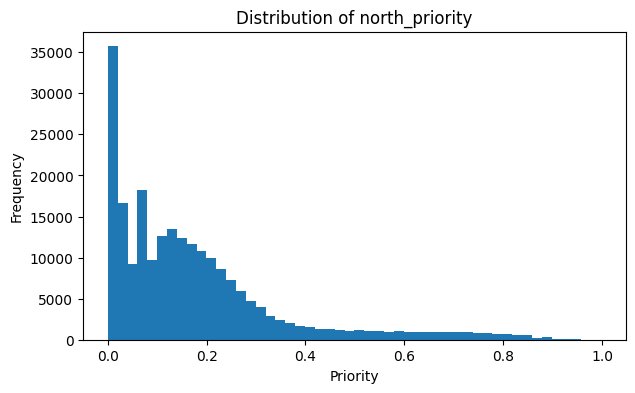

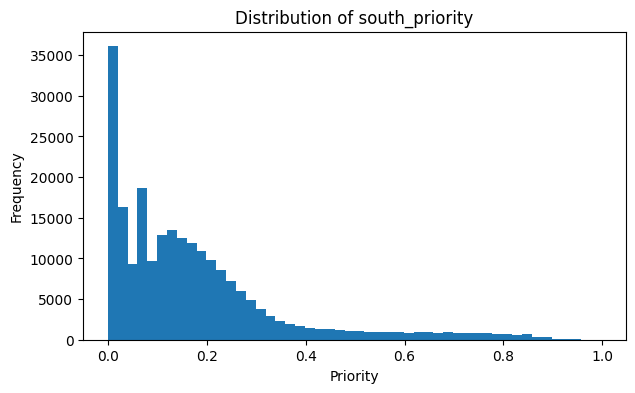

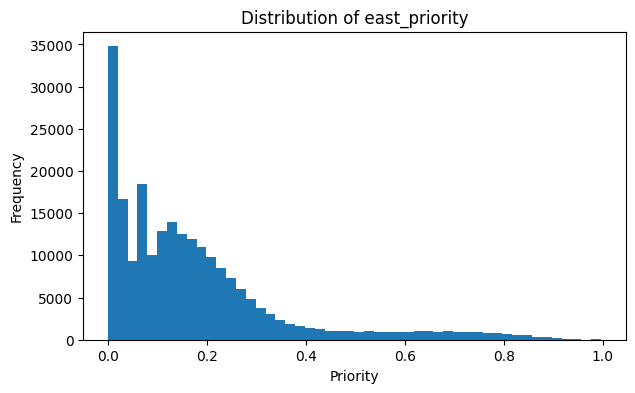

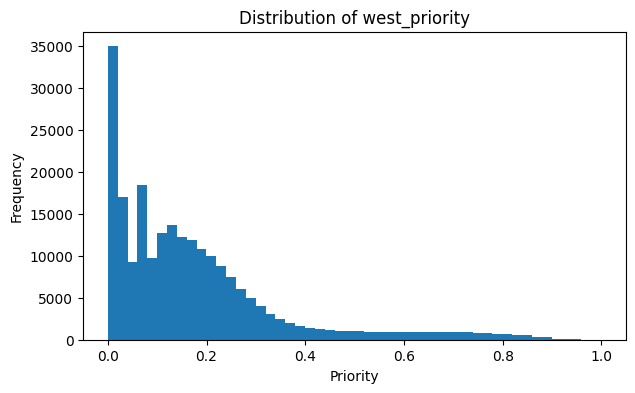

In [24]:
for column in target_columns:

    plt.figure(figsize=(7, 4))

    plt.hist(
        df[column],
        bins=50
    )

    plt.xlabel("Priority")
    plt.ylabel("Frequency")
    plt.title(f"Distribution of {column}")

    plt.show()

In [25]:
for approach in approaches:

    target = f"{approach}_priority"

    waiting = f"{approach}_waiting"
    queue = f"{approach}_queue"

    print(f"\n===== {approach.upper()} =====")

    print(
        "Priority ↔ Waiting:",
        df[target].corr(df[waiting])
    )

    print(
        "Priority ↔ Queue:",
        df[target].corr(df[queue])
    )

    print(
        "Priority ↔ Speed:",
        df[target].corr(df[f"{approach}_speed"])
    )


===== NORTH =====
Priority ↔ Waiting: 0.9312405707185114
Priority ↔ Queue: 0.9396836647311619
Priority ↔ Speed: -0.491757478080832

===== SOUTH =====
Priority ↔ Waiting: 0.9308959798399538
Priority ↔ Queue: 0.9412111965921642
Priority ↔ Speed: -0.48961896874861904

===== EAST =====
Priority ↔ Waiting: 0.9299117360721496
Priority ↔ Queue: 0.9371847940896181
Priority ↔ Speed: -0.49700795530102143

===== WEST =====
Priority ↔ Waiting: 0.9276388672320909
Priority ↔ Queue: 0.937434447590971
Priority ↔ Speed: -0.49626640706044545


In [26]:
for approach in approaches:

    vehicles = df[
        f"{approach}_vehicles"
    ]

    priority = df[
        f"{approach}_priority"
    ]

    invalid = (
        (vehicles == 0)
        & (priority != 0)
    ).sum()

    print(
        approach,
        "invalid empty priorities:",
        invalid
    )

north invalid empty priorities: 0
south invalid empty priorities: 0
east invalid empty priorities: 0
west invalid empty priorities: 0


In [27]:
row = df.iloc[100]
approach = "north"

In [28]:
manual = (
    0.35 * row["north_norm_waiting"] ** 1.4
    + 0.25 * row["north_norm_queue"]
    + 0.15 * row["north_norm_arrivals"]
    + 0.10 * row["north_norm_density"]
    + 0.10 * (1 - row["north_norm_speed"])
    + 0.05 * row["north_norm_pressure"]
)

print("Manual:", manual)
print(
    "Generated:",
    row["north_priority"]
)

Manual: 0.12368980879978478
Generated: 0.12368980879978478


In [29]:
mlp_features = []

for approach in approaches:
    for feature in approach_input_features:
        mlp_features.append(
            f"{approach}_{feature}"
        )

In [30]:
mlp_features += global_features

In [31]:
print(
    "Total raw MLP features:",
    len(mlp_features)
)

for i, feature in enumerate(mlp_features):
    print(i, feature)

Total raw MLP features: 39
0 north_queue
1 north_waiting
2 north_speed
3 north_density
4 north_pressure
5 north_arrivals
6 north_departures
7 north_emergency
8 north_emergency_waiting
9 south_queue
10 south_waiting
11 south_speed
12 south_density
13 south_pressure
14 south_arrivals
15 south_departures
16 south_emergency
17 south_emergency_waiting
18 east_queue
19 east_waiting
20 east_speed
21 east_density
22 east_pressure
23 east_arrivals
24 east_departures
25 east_emergency
26 east_emergency_waiting
27 west_queue
28 west_waiting
29 west_speed
30 west_density
31 west_pressure
32 west_arrivals
33 west_departures
34 west_emergency
35 west_emergency_waiting
36 phase
37 phase_time
38 total_vehicles


In [32]:
scenario_ids = df[scenario_column].unique()

print("No. of scenarios : ",len(scenario_ids))

No. of scenarios :  300


In [33]:
train_scenarios, temp_scenarios = train_test_split(
    scenario_ids,
    test_size=0.20,
    random_state=42
)

In [34]:
val_scenarios, test_scenarios = train_test_split(
    temp_scenarios,
    test_size=0.50,
    random_state=42
)

In [35]:
print("Train: ", len(train_scenarios))
print("Validation: ", len(val_scenarios))
print("Test: ", len(test_scenarios))

Train:  240
Validation:  30
Test:  30


In [36]:
train_df = df[df["scenario_id"].isin(train_scenarios)].copy()

val_df = df[df["scenario_id"].isin(val_scenarios)].copy()

test_df = df[df["scenario_id"].isin(test_scenarios)].copy()

In [37]:
print(
    "Rows:",
    len(train_df),
    len(val_df),
    len(test_df)
)

Rows: 178506 22305 22349


In [38]:
assert set(
    train_df["scenario_id"]
).isdisjoint(
    val_df["scenario_id"]
)

assert set(
    train_df["scenario_id"]
).isdisjoint(
    test_df["scenario_id"]
)

assert set(
    val_df["scenario_id"]
).isdisjoint(
    test_df["scenario_id"]
)

print("Scenario split is clean.")

Scenario split is clean.


In [39]:
numerical_features = [
    column
    for column in mlp_features
    if column != 'phase'
]

In [40]:
categorical_features = ['phase']

In [41]:
numeric_pipeline = Pipeline([
    (
        'scaler',
        StandardScaler()
    )
])

categorical_pipeline = Pipeline([
    (
        'onehot',
        OneHotEncoder(
            handle_unknown='ignore',
            sparse_output=False
        )
    )
])

Preprocessor = ColumnTransformer(
    transformers=[
        (
            'numeric',
            numeric_pipeline,
            numerical_features
        ),
        (
            "categorical",
            categorical_pipeline,
            categorical_features
        )
    ],
    remainder = 'drop'
)

In [42]:
X_train_raw = train_df[mlp_features].copy()
X_val_raw = val_df[mlp_features].copy()
X_test_raw = test_df[mlp_features].copy()

Preprocessor.fit(X_train_raw)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('scaler', StandardScaler())]),
                                 ['north_queue', 'north_waiting', 'north_speed',
                                  'north_density', 'north_pressure',
                                  'north_arrivals', 'north_departures',
                                  'north_emergency', 'north_emergency_waiting',
                                  'south_queue', 'south_waiting', 'south_speed',
                                  'south_density', 'south_pressure',
                                  'south_arrivals', 'south_de...
                                  'south_emergency', 'south_emergency_waiting',
                                  'east_queue', 'east_waiting', 'east_speed',
                                  'east_density', 'east_pressure',
                                  'east_arrivals', 'east_departures',
                                  'east_emergency', 'east_emergency_waiting',
                                  'west_queue', 'west_waiting', 'west_speed', ...]),
                                ('categorical',
                                 Pipeline(steps=[('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['phase'])])

In [43]:
X_train = Preprocessor.transform(X_train_raw)
X_val = Preprocessor.transform(X_val_raw)
X_test = Preprocessor.transform(X_test_raw)

print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)

X_train: (178506, 42)
X_val: (22305, 42)
X_test: (22349, 42)


In [44]:
joblib.dump(
    Preprocessor,
    ARTIFACT_DIR / "preprocessor.joblib"
)

print("Saved sklearn preprocessing pipeline.")

Saved sklearn preprocessing pipeline.


In [45]:
y_train = train_df[target_columns].values.astype(np.float64)
y_val = val_df[target_columns].values.astype(np.float64)
y_test = test_df[target_columns].values.astype(np.float64)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)

y_train: (178506, 4)
y_val: (22305, 4)
y_test: (22349, 4)


In [46]:
X_train_tensor = torch.tensor(X_train,dtype=torch.float32)
X_val_tensor = torch.tensor(X_val,dtype=torch.float32)
X_test_tensor = torch.tensor(X_test,dtype=torch.float32)
y_train_tensor = torch.tensor(y_train,dtype=torch.float32)
y_val_tensor = torch.tensor(y_val,dtype=torch.float32)
y_test_tensor = torch.tensor(y_test,dtype=torch.float32)

In [47]:
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

In [48]:
class TrafficPriorityMLP(nn.Module):

    def __init__(
        self, 
        input_dim,
        dropout1,
        dropout2,
        dropout3,
    ):

        super().__init__()

        self.network = nn.Sequential(
            
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(dropout1),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(dropout2),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(dropout3),

            nn.Linear(32, 4),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

In [61]:
def objective(trial):

    #============HyperParameters============#

    lr = trial.suggest_float(
        'learning_rate', 1e-5, 3e-3, log=True
    )

    wd = trial.suggest_float(
        'weight_decay', 1e-7, 1e-3, log=True
    )

    dropout1 = trial.suggest_float(
        "dropout1", 0.10, 0.40
    )

    dropout2 = trial.suggest_float(
        "dropout2", 0.05, 0.30
    )

    dropout3 = trial.suggest_float(
        "dropout3", 0.00, 0.25
    )

    batch_size = trial.suggest_categorical(
        "batch_size", [128, 256, 512]
    )


    #==============Data Loaders==================#
    
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True
    )

    val_loader = DataLoader(
        val_dataset, batch_size=batch_size, shuffle=False
    )


    #=============Model=====================#

    model = TrafficPriorityMLP(
        input_dim=X_train.shape[1], dropout1=dropout1, dropout2=dropout2, dropout3=dropout3
    ).to(device)

    #=============LOSS======================#
    
    criterion = nn.SmoothL1Loss()


    #==================Optimizer=================#

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr = lr,
        weight_decay=wd
    )


    #=============Training Settings=================#


    best_val_loss = float("inf")
    patience_counter = 0
    trial_epochs = 100
    trial_patience = 10

    #================Train===============#

    for epoch in range(trial_epochs):

        model.train()
        train_loss_total =  0.0

        for X_batch, y_batch in train_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            optimizer.zero_grad()

            predictions = model(X_batch)

            loss = criterion(predictions, y_batch)

            loss.backward()

            optimizer.step()

            train_loss_total += (loss.item()*X_batch.size(0))

        train_loss = (train_loss_total / len(train_loader.dataset))

        #================Validation==================#
    
        model.eval()
    
        val_loss_total = 0.0
    
        with torch.no_grad():
    
            for X_batch, y_batch in val_loader:
    
                X_batch = X_batch.to(device)
                y_batch = y_batch.to(device)

                predictions = model(X_batch)
    
                loss = criterion(predictions, y_batch)
    
                val_loss_total += (loss.item()*X_batch.size(0))
    
        val_loss = (val_loss_total/len(val_loader.dataset))
    
    
        #=================Optuna Reporting=================#

        trial.report(
            val_loss,
            epoch
        )

        #=========Verbose Output==============#

        print(
            f"Trial {trial.number:02d} | "
            f"Epoch {epoch + 1:03d}/{trial_epochs} | "
            f"Train Loss: {train_loss:.6f} | "
            f"Val Loss: {val_loss:.6f}"
        )

        #============Pruning====================#

        if trial.should_prune():

            print(
                f"Trial {trial.number:02d} pruned "
                f"at epoch {epoch + 1}"
            )

            raise optuna.TrialPruned()
    
        # ============= Early Stopping =============

        if val_loss < best_val_loss:
        
            best_val_loss = val_loss
            patience_counter = 0
        
        else:
        
            patience_counter += 1
        
        
        if patience_counter >= trial_patience:
        
            print(
                f"Trial {trial.number:02d} early stopped "
                f"at epoch {epoch + 1}"
            )
        
            break

    return best_val_loss

In [63]:
study = optuna.create_study(
    direction="minimize",
    study_name="traffic_priority_mlp"
)

study.optimize(
    objective,
    n_trials=25
)

[I 2026-08-27 13:05:45,053] A new study created in memory with name: traffic_priority_mlp


Trial 00 | Epoch 001/100 | Train Loss: 0.005281 | Val Loss: 0.000367
Trial 00 | Epoch 002/100 | Train Loss: 0.001054 | Val Loss: 0.000225
Trial 00 | Epoch 003/100 | Train Loss: 0.000903 | Val Loss: 0.000187
Trial 00 | Epoch 004/100 | Train Loss: 0.000808 | Val Loss: 0.000165
Trial 00 | Epoch 005/100 | Train Loss: 0.000756 | Val Loss: 0.000169
Trial 00 | Epoch 006/100 | Train Loss: 0.000720 | Val Loss: 0.000137
Trial 00 | Epoch 007/100 | Train Loss: 0.000684 | Val Loss: 0.000132
Trial 00 | Epoch 008/100 | Train Loss: 0.000644 | Val Loss: 0.000140
Trial 00 | Epoch 009/100 | Train Loss: 0.000635 | Val Loss: 0.000111
Trial 00 | Epoch 010/100 | Train Loss: 0.000612 | Val Loss: 0.000098
Trial 00 | Epoch 011/100 | Train Loss: 0.000601 | Val Loss: 0.000102
Trial 00 | Epoch 012/100 | Train Loss: 0.000586 | Val Loss: 0.000097
Trial 00 | Epoch 013/100 | Train Loss: 0.000576 | Val Loss: 0.000087
Trial 00 | Epoch 014/100 | Train Loss: 0.000568 | Val Loss: 0.000099
Trial 00 | Epoch 015/100 | Train L

[I 2026-08-27 13:11:07,481] Trial 0 finished with value: 5.9262925190947125e-05 and parameters: {'learning_rate': 0.0006584307492832827, 'weight_decay': 0.00023443383754989615, 'dropout1': 0.14847903250000405, 'dropout2': 0.24136329020165376, 'dropout3': 0.06192263100317155, 'batch_size': 128}. Best is trial 0 with value: 5.9262925190947125e-05.


Trial 00 | Epoch 072/100 | Train Loss: 0.000426 | Val Loss: 0.000059
Trial 00 early stopped at epoch 72
Trial 01 | Epoch 001/100 | Train Loss: 0.044350 | Val Loss: 0.029839
Trial 01 | Epoch 002/100 | Train Loss: 0.021827 | Val Loss: 0.014629
Trial 01 | Epoch 003/100 | Train Loss: 0.011214 | Val Loss: 0.007162
Trial 01 | Epoch 004/100 | Train Loss: 0.006139 | Val Loss: 0.003880
Trial 01 | Epoch 005/100 | Train Loss: 0.003824 | Val Loss: 0.002289
Trial 01 | Epoch 006/100 | Train Loss: 0.002706 | Val Loss: 0.001458
Trial 01 | Epoch 007/100 | Train Loss: 0.002105 | Val Loss: 0.001022
Trial 01 | Epoch 008/100 | Train Loss: 0.001753 | Val Loss: 0.000779
Trial 01 | Epoch 009/100 | Train Loss: 0.001527 | Val Loss: 0.000601
Trial 01 | Epoch 010/100 | Train Loss: 0.001376 | Val Loss: 0.000496
Trial 01 | Epoch 011/100 | Train Loss: 0.001273 | Val Loss: 0.000454
Trial 01 | Epoch 012/100 | Train Loss: 0.001201 | Val Loss: 0.000434
Trial 01 | Epoch 013/100 | Train Loss: 0.001149 | Val Loss: 0.000360

[I 2026-08-27 13:15:54,922] Trial 1 finished with value: 0.00011194139497765486 and parameters: {'learning_rate': 3.94970681116882e-05, 'weight_decay': 1.2859242296673327e-06, 'dropout1': 0.35736511319327136, 'dropout2': 0.08243222204932511, 'dropout3': 0.04977973591225596, 'batch_size': 256}. Best is trial 0 with value: 5.9262925190947125e-05.


...

Trial 22 | Epoch 001/100 | Train Loss: 0.005892 | Val Loss: 0.000473
Trial 22 pruned at epoch 1


[I 2026-08-27 13:42:36,541] Trial 23 pruned. 


Trial 23 | Epoch 001/100 | Train Loss: 0.026739 | Val Loss: 0.007066
Trial 23 pruned at epoch 1


[I 2026-08-27 13:42:38,589] Trial 24 pruned. 


Trial 24 | Epoch 001/100 | Train Loss: 0.009444 | Val Loss: 0.000581
Trial 24 pruned at epoch 1


In [64]:
print("Best trial:")
print(study.best_trial)

print("\nBest validation loss:")
print(study.best_value)

print("\nBest hyperparameters:")
for key, value in study.best_params.items():
    print(f"{key}: {value}")

Best trial:
FrozenTrial(number=15, state=<TrialState.COMPLETE: 1>, values=[4.423703369329609e-05], datetime_start=datetime.datetime(2026, 8, 27, 13, 38, 25, 117264), datetime_complete=datetime.datetime(2026, 8, 27, 13, 40, 29, 898849), params={'learning_rate': 0.001216052553406429, 'weight_decay': 3.3108510831042274e-06, 'dropout1': 0.19455273277569726, 'dropout2': 0.1786944473354618, 'dropout3': 0.04107425436374876, 'batch_size': 512}, user_attrs={}, system_attrs={}, intermediate_values={0: 0.000378818181098072, 1: 0.0002674498957800191, 2: 0.00020045821776750754, 3: 0.0001848418378943193, 4: 0.00017575159229279088, 5: 0.0001538727519859603, 6: 0.00015013450541636036, 7: 0.00012079873851795235, 8: 0.00012961013299727015, 9: 9.840109480905679e-05, 10: 0.0001062367431449603, 11: 0.0001137374233313755, 12: 7.548554497290795e-05, 13: 0.00011764831235272173, 14: 8.314127078929335e-05, 15: 6.791885309752242e-05, 16: 7.587584814455922e-05, 17: 6.934462714834045e-05, 18: 5.907160397257837e-05

In [65]:
print("Total trials:", len(study.trials))

print("\nTrial states:")
print(study.trials_dataframe()["state"].value_counts())

print("\nTop 10 trials:")
print(
    study.trials_dataframe()
    .sort_values("value")
    [["number", "value", "state"]]
    .head(10)
)

Total trials: 25

Trial states:
state
COMPLETE    13
PRUNED      12
Name: count, dtype: int64

Top 10 trials:
    number     value     state
15      15  0.000044  COMPLETE
8        8  0.000048  COMPLETE
17      17  0.000050  COMPLETE
12      12  0.000055  COMPLETE
0        0  0.000059  COMPLETE
4        4  0.000059  COMPLETE
11      11  0.000061  COMPLETE
13      13  0.000080  COMPLETE
9        9  0.000083  COMPLETE
3        3  0.000084  COMPLETE


In [66]:
BEST_PARAMS = study.best_params

print(BEST_PARAMS)

{'learning_rate': 0.001216052553406429, 'weight_decay': 3.3108510831042274e-06, 'dropout1': 0.19455273277569726, 'dropout2': 0.1786944473354618, 'dropout3': 0.04107425436374876, 'batch_size': 512}


In [67]:
final_model = TrafficPriorityMLP(
    input_dim=X_train.shape[1],

    dropout1=BEST_PARAMS["dropout1"],
    dropout2=BEST_PARAMS["dropout2"],
    dropout3=BEST_PARAMS["dropout3"]
).to(device)

In [68]:
print(final_model)

TrafficPriorityMLP(
  (network): Sequential(
    (0): Linear(in_features=42, out_features=128, bias=True)
    (1): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Dropout(p=0.19455273277569726, inplace=False)
    (4): Linear(in_features=128, out_features=64, bias=True)
    (5): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU()
    (7): Dropout(p=0.1786944473354618, inplace=False)
    (8): Linear(in_features=64, out_features=32, bias=True)
    (9): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Dropout(p=0.04107425436374876, inplace=False)
    (12): Linear(in_features=32, out_features=4, bias=True)
    (13): Sigmoid()
  )
)


In [69]:
final_train_loader = DataLoader(
    train_dataset,
    batch_size=BEST_PARAMS["batch_size"],
    shuffle=True
)

final_val_loader = DataLoader(
    val_dataset,
    batch_size=BEST_PARAMS["batch_size"],
    shuffle=False
)

In [70]:
criterion = nn.SmoothL1Loss()

optimizer = torch.optim.AdamW(
    final_model.parameters(),
    lr=BEST_PARAMS["learning_rate"],
    weight_decay=BEST_PARAMS["weight_decay"]
)

In [71]:
FINAL_EPOCHS = 150
FINAL_PATIENCE = 15

best_val_loss = float("inf")
patience_counter = 0

best_model_path = ARTIFACT_DIR / "final_model.pt"

history = {
    "train_loss": [],
    "val_loss": []
}

In [72]:
for epoch in range(FINAL_EPOCHS):

    #==================TRAIN====================#

    final_model.train()

    train_loss_total = 0.0

    for X_batch, y_batch in final_train_loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = final_model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        optimizer.step()

        train_loss_total += (
            loss.item() * X_batch.size(0)
        )

    train_loss = (
        train_loss_total /
        len(final_train_loader.dataset)
    )


    #===============VALIDATION===================#

    final_model.eval()

    val_loss_total = 0.0

    with torch.no_grad():

        for X_batch, y_batch in final_val_loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = final_model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            val_loss_total += (
                loss.item() * X_batch.size(0)
            )

    val_loss = (
        val_loss_total /
        len(final_val_loader.dataset)
    )


    #===============SAVE HISTORY==================#

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)


    #============BEST MODEL===============#

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            final_model.state_dict(),
            best_model_path
        )

    else:

        patience_counter += 1


    #===============VERBOSE OUTPUT=====================#

    print(
        f"Epoch {epoch + 1:03d}/{FINAL_EPOCHS} | "
        f"Train Loss: {train_loss:.6f} | "
        f"Val Loss: {val_loss:.6f}"
    )


    #===================EARLY STOPPING=================#

    if patience_counter >= FINAL_PATIENCE:

        print(
            f"\nEarly stopping at epoch "
            f"{epoch + 1}"
        )

        break

Epoch 001/150 | Train Loss: 0.007864 | Val Loss: 0.000455
Epoch 002/150 | Train Loss: 0.000966 | Val Loss: 0.000291
Epoch 003/150 | Train Loss: 0.000802 | Val Loss: 0.000222
Epoch 004/150 | Train Loss: 0.000722 | Val Loss: 0.000178
Epoch 005/150 | Train Loss: 0.000665 | Val Loss: 0.000169
Epoch 006/150 | Train Loss: 0.000621 | Val Loss: 0.000161
Epoch 007/150 | Train Loss: 0.000588 | Val Loss: 0.000173
Epoch 008/150 | Train Loss: 0.000560 | Val Loss: 0.000146
Epoch 009/150 | Train Loss: 0.000541 | Val Loss: 0.000128
Epoch 010/150 | Train Loss: 0.000518 | Val Loss: 0.000127
Epoch 011/150 | Train Loss: 0.000501 | Val Loss: 0.000099
Epoch 012/150 | Train Loss: 0.000485 | Val Loss: 0.000108
Epoch 013/150 | Train Loss: 0.000466 | Val Loss: 0.000105
Epoch 014/150 | Train Loss: 0.000458 | Val Loss: 0.000087
Epoch 015/150 | Train Loss: 0.000439 | Val Loss: 0.000086
Epoch 016/150 | Train Loss: 0.000427 | Val Loss: 0.000100
Epoch 017/150 | Train Loss: 0.000413 | Val Loss: 0.000080
Epoch 018/150 

In [73]:
final_model.load_state_dict(
    torch.load(
        best_model_path,
        map_location=device
    )
)

final_model.eval()

print(
    f"Best validation loss: "
    f"{best_val_loss:.8f}"
)

Best validation loss: 0.00004591


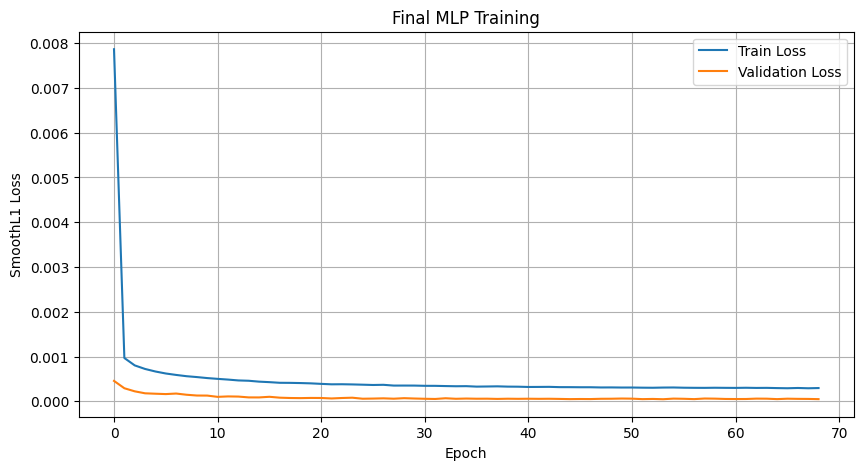

In [74]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("SmoothL1 Loss")
plt.title("Final MLP Training")

plt.legend()
plt.grid(True)

plt.show()

In [77]:
test_dataset = TensorDataset(
    X_test_tensor,
    y_test_tensor
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BEST_PARAMS["batch_size"],
    shuffle=False
)

In [78]:
all_predictions = []
all_targets = []

final_model.eval()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(device)

        predictions = final_model(X_batch)

        all_predictions.append(
            predictions.cpu().numpy()
        )

        all_targets.append(
            y_batch.numpy()
        )


y_pred = np.concatenate(
    all_predictions,
    axis=0
)

y_true = np.concatenate(
    all_targets,
    axis=0
)

print("y_true shape:", y_true.shape)
print("y_pred shape:", y_pred.shape)

y_true shape: (22349, 4)
y_pred shape: (22349, 4)


In [80]:
for i, approach in enumerate(approaches):

    mae = mean_absolute_error(
        y_true[:, i],
        y_pred[:, i]
    )

    rmse = np.sqrt(
        mean_squared_error(
            y_true[:, i],
            y_pred[:, i]
        )
    )

    r2 = r2_score(
        y_true[:, i],
        y_pred[:, i]
    )

    print(
        f"{approach.upper():5s} | "
        f"MAE: {mae:.6f} | "
        f"RMSE: {rmse:.6f} | "
        f"R²: {r2:.6f}"
    )

NORTH | MAE: 0.006555 | RMSE: 0.010329 | R²: 0.997141
SOUTH | MAE: 0.007485 | RMSE: 0.012239 | R²: 0.995089
EAST  | MAE: 0.006722 | RMSE: 0.010452 | R²: 0.997138
WEST  | MAE: 0.007378 | RMSE: 0.011354 | R²: 0.996332


In [81]:
true_winner = np.argmax(
    y_true,
    axis=1
)

pred_winner = np.argmax(
    y_pred,
    axis=1
)

top1_accuracy = np.mean(
    true_winner == pred_winner
)

print(
    f"Top-1 Priority Accuracy: "
    f"{top1_accuracy:.4%}"
)

Top-1 Priority Accuracy: 95.8924%


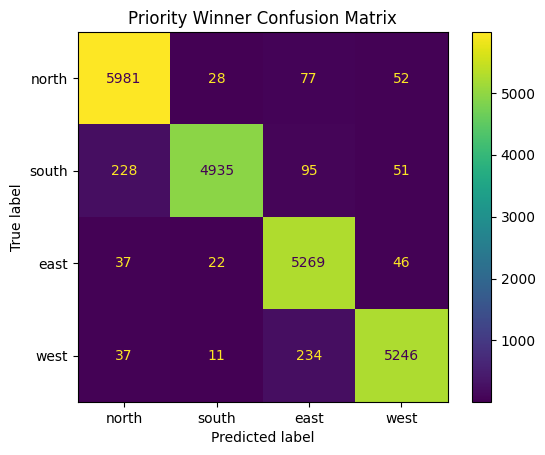

In [82]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    true_winner,
    pred_winner,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=approaches
)

disp.plot()

plt.title("Priority Winner Confusion Matrix")
plt.show()

In [83]:
true_sorted = np.sort(
    y_true,
    axis=1
)

true_margin = (
    true_sorted[:, -1] -
    true_sorted[:, -2]
)

print(
    "Median true winner margin:",
    np.median(true_margin)
)

print(
    "Mean true winner margin:",
    np.mean(true_margin)
)

Median true winner margin: 0.05714722
Mean true winner margin: 0.07916851
